Week 9 notebook, gradient boosting, Mike Hembree

Same project as the earlier weeks. The capstone is an early warning model for ICU delirium on MIMIC IV, and the MIMIC part of this notebook runs on the MIMIC IV Clinical Database Demo (100 patients, 140 ICU stays) because the full credentialed access is still pending. The second dataset is the ECAMS EEG data from Massachusetts General Hospital (373 patients, 1189 EEG features, delirium called by the CAM algorithm), the same two datasets as the Milestone One notebooks. Same validation as Week 8, repeated stratified five fold cross validation with three repeats, and anything tuned is tuned inside each training fold. Gradient boosting builds small trees one after another, each one fit to the mistakes of the trees before it, and the knobs I care about are the learning rate, the number of rounds, tree depth, and the regularization options sklearn has (row subsampling, minimum leaf size, feature subsampling, and early stopping). All fits use max_features of sqrt unless noted, which keeps the 1189 column ECAMS runs fast.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, accuracy_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'

In [2]:
# load both datasets, the mimic feature table was saved by the Week 8 notebook
feat = pd.read_csv('delirium_features.csv')
mcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min']
Xm = feat[mcols]
ym = feat['delirium_positive']

Xe = pd.read_csv('ecams/features_alldata.csv')
clin = pd.read_csv('ecams/E_CAM_S_Data.csv').sort_values('SubjectID-used_for_feature_extraction').reset_index(drop = True)
ye = clin['CAM algorithm (CAM 1 & 2 , and 3 or 4 SATISFIED - DELIRIUM POSITIVE)'].astype(int)

data = {'mimic': (Xm, ym), 'ecams': (Xe, ye)}
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
splits = {k: train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y) for k, (X, y) in data.items()}
for k, (X, y) in data.items():
    print(k, X.shape, 'positive rate', round(y.mean(), 3))

mimic (140, 9) positive rate 0.321
ecams (373, 1189) positive rate 0.681


In [3]:
# gradient boosting helper, a staged cv curve gives train and validation auc after every tree
def gb_model(**kw):
    base = dict(n_estimators = 300, learning_rate = 0.1, max_depth = 2, random_state = 0)
    if 'max_features' not in kw:
        kw['max_features'] = 'sqrt'
    base.update(kw)
    return make_pipeline(SimpleImputer(strategy = 'median'), GradientBoostingClassifier(**base))

def staged_cv(name, n_splits = 5, n_repeats = 3, **kw):
    X, y = data[name]
    cv = RepeatedStratifiedKFold(n_splits = n_splits, n_repeats = n_repeats, random_state = 1)
    tr_curves, va_curves = [], []
    for a, b in cv.split(X, y):
        m = gb_model(**kw).fit(X.iloc[a], y.iloc[a])
        imp = m[0]
        Xa = imp.transform(X.iloc[a])
        Xb = imp.transform(X.iloc[b])
        tr_curves.append([roc_auc_score(y.iloc[a], p[:, 1]) for p in m[1].staged_predict_proba(Xa)])
        va_curves.append([roc_auc_score(y.iloc[b], p[:, 1]) for p in m[1].staged_predict_proba(Xb)])
    return np.mean(tr_curves, axis = 0), np.mean(va_curves, axis = 0)

curves = {}
for name in data:
    for lr in [0.01, 0.03, 0.1, 0.3]:
        curves[(name, 'lr', lr)] = staged_cv(name, learning_rate = lr, max_depth = 2)
    for d in [1, 2, 3, 5]:
        curves[(name, 'depth', d)] = staged_cv(name, learning_rate = 0.1, max_depth = d)
rows = []
for (name, kind, v), (tr, va) in curves.items():
    rows.append({'data': name, 'varied': kind, 'value': v, 'best round': int(va.argmax()) + 1, 'best val auc': va.max(), 'val auc at 300': va[-1], 'train auc at 300': tr[-1]})
stage_tab = pd.DataFrame(rows)
stage_tab.to_csv('figs/w9_stage_summary.csv', index = False)
stage_tab.round(3)

,data,varied,value,best round,best val auc,val auc at 300,train auc at 300
0,mimic,lr,0.01,297,0.777,0.777,0.978
1,mimic,lr,0.03,118,0.778,0.750,0.999
2,mimic,lr,0.10,30,0.776,0.740,1.000
3,mimic,lr,0.30,9,0.786,0.730,1.000
4,mimic,depth,1.00,80,0.781,0.748,0.992
5,mimic,depth,2.00,30,0.776,0.740,1.000
6,mimic,depth,3.00,18,0.773,0.726,1.000
7,mimic,depth,5.00,19,0.759,0.741,1.000
8,ecams,lr,0.01,300,0.897,0.897,0.985
9,ecams,lr,0.03,90,0.895,0.888,1.000


Training auc reaches 1.0 or very close in every setting except the slowest learning rate, so what matters is the validation column. On MIMIC the validation auc peaks early and then slides down as more rounds are added. Learning rate 0.3 peaks at round 9 (0.786) and is at 0.730 by round 300, 0.1 peaks at round 30 and ends at 0.740, 0.03 peaks around round 118 and ends at 0.750, and only 0.01 is still creeping up at round 297 (0.777). Smaller learning rates give a higher number at 300 rounds, but the best validation auc is about 0.78 for every one of them, so the learning rate mostly changes how many rounds you can run before the model starts memorizing. Depth showed the same thing, depth 1 reached 0.781 at round 80, while depth 5 peaked at 0.759. ECAMS is much flatter, all settings sit between 0.886 and 0.897, the slowest learning rate is best at 0.897 and the fastest drifts down from 0.886 to 0.874. Deeper trees were a little better on ECAMS (depth 5 holds 0.893 at 300 rounds where depth 1 falls to 0.877), which is the opposite of MIMIC and probably reflects ECAMS having more rows and many redundant features to choose from.

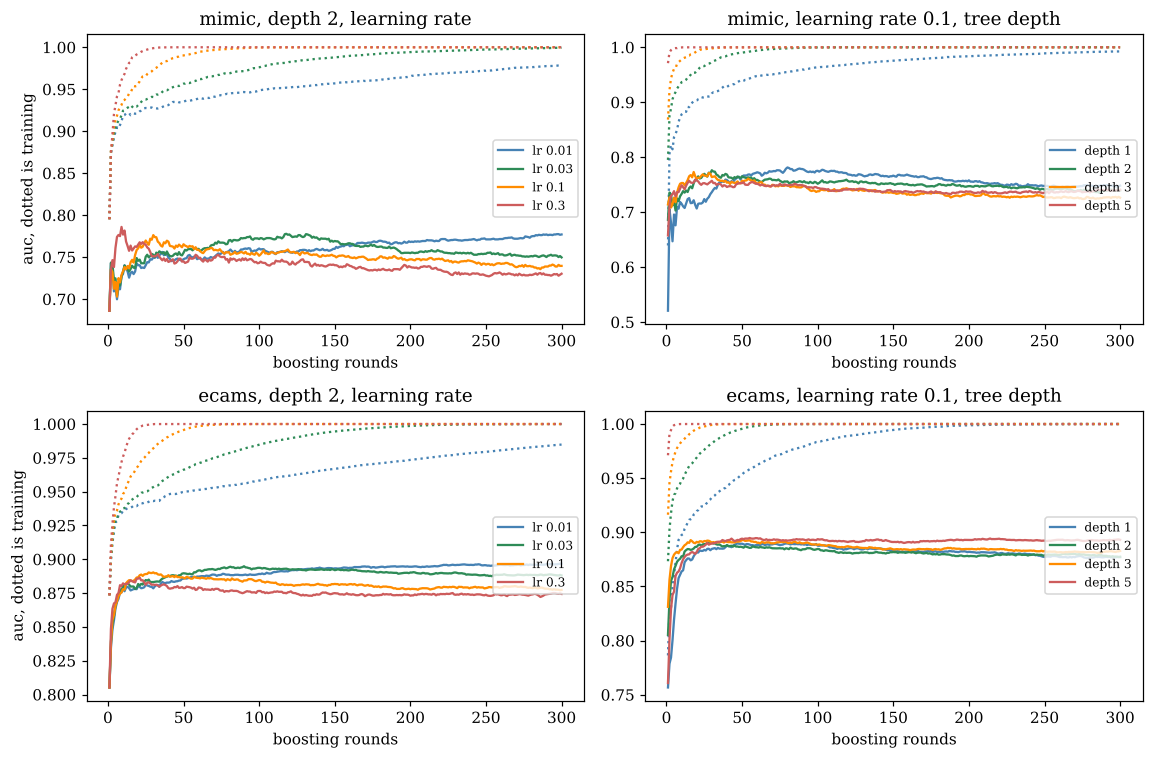

In [4]:
# figure, validation auc by boosting round for four learning rates and four depths
fig, ax = plt.subplots(2, 2, figsize = (10.5, 7))
for i, name in enumerate(data):
    for lr, c in zip([0.01, 0.03, 0.1, 0.3], ['steelblue', 'seagreen', 'darkorange', 'indianred']):
        tr, va = curves[(name, 'lr', lr)]
        ax[i, 0].plot(np.arange(1, 301), va, color = c, label = 'lr ' + str(lr))
        ax[i, 0].plot(np.arange(1, 301), tr, color = c, linestyle = ':')
    ax[i, 0].set_xlabel('boosting rounds')
    ax[i, 0].set_ylabel('auc, dotted is training')
    ax[i, 0].set_title(name + ', depth 2, learning rate')
    ax[i, 0].legend(fontsize = 8, loc = 'center right')
    for d, c in zip([1, 2, 3, 5], ['steelblue', 'seagreen', 'darkorange', 'indianred']):
        tr, va = curves[(name, 'depth', d)]
        ax[i, 1].plot(np.arange(1, 301), va, color = c, label = 'depth ' + str(d))
        ax[i, 1].plot(np.arange(1, 301), tr, color = c, linestyle = ':')
    ax[i, 1].set_xlabel('boosting rounds')
    ax[i, 1].set_title(name + ', learning rate 0.1, tree depth')
    ax[i, 1].legend(fontsize = 8, loc = 'center right')
plt.tight_layout()
plt.savefig('figs/w9_staged.png', dpi = 200)
plt.show()

In [5]:
# regularization knobs one at a time at learning rate 0.1, depth 3, 150 rounds
settings = {
    'plain': dict(),
    'subsample 0.5': dict(subsample = 0.5),
    'min leaf 5': dict(min_samples_leaf = 5),
    'min leaf 10': dict(min_samples_leaf = 10),
    'max features 0.05': dict(max_features = 0.05),
    'max features all': dict(max_features = None),
    'subsample 0.5, min leaf 5': dict(subsample = 0.5, min_samples_leaf = 5)
}
rows = []
for name in data:
    for sn, kw in settings.items():
        if name == 'mimic' and 'max features 0.05' in sn:
            continue
        r = cross_validate(gb_model(n_estimators = 150, learning_rate = 0.1, max_depth = 3, **kw), data[name][0], data[name][1], cv = cv_clf, scoring = 'roc_auc', return_train_score = True, n_jobs = 2)
        rows.append({'data': name, 'setting': sn, 'train auc': r['train_score'].mean(), 'cv auc': r['test_score'].mean(), 'gap': r['train_score'].mean() - r['test_score'].mean()})
reg_tab = pd.DataFrame(rows)
reg_tab.to_csv('figs/w9_regularization.csv', index = False)
reg_tab.round(3)

,data,setting,train auc,cv auc,gap
0,mimic,plain,1.0,0.735,0.265
1,mimic,subsample 0.5,1.0,0.748,0.252
2,mimic,min leaf 5,1.0,0.724,0.276
3,mimic,min leaf 10,1.0,0.741,0.259
4,mimic,max features all,1.0,0.730,0.270
5,mimic,"subsample 0.5, min leaf 5",1.0,0.770,0.230
6,ecams,plain,1.0,0.884,0.116
7,ecams,subsample 0.5,1.0,0.886,0.114
8,ecams,min leaf 5,1.0,0.888,0.112
9,ecams,min leaf 10,1.0,0.888,0.112


Training auc is 1.0 in every row, so none of these controls stops the model from memorizing the training folds, they just change how much it hurts. On MIMIC row subsampling at 0.5 helps a bit (0.748 against 0.735 plain) and combining it with a minimum leaf of 5 gives the best result at 0.770, while the minimum leaf alone does nothing reliable (0.724 at 5, 0.741 at 10). That's one run of a noisy estimate with an sd of about 0.1 per fold, so I'm not claiming the 0.77 is real. On ECAMS the effects are tiny, 0.884 plain against 0.888 with a minimum leaf of 5 or 10. The one clear effect is that using every feature at each split (0.867) is worse than sampling sqrt of them (0.884), so feature subsampling works as regularization when the columns are this redundant.

In [6]:
# early stopping, let the model quit when a held out slice of the training fold stops improving
rows = []
for name in data:
    for nic in [5, 10, 20]:
        X, y = data[name]
        used = []
        aucs = []
        for a, b in cv_clf.split(X, y):
            m = gb_model(n_estimators = 500, learning_rate = 0.1, max_depth = 2, n_iter_no_change = nic, validation_fraction = 0.2).fit(X.iloc[a], y.iloc[a])
            used.append(m[1].n_estimators_)
            aucs.append(roc_auc_score(y.iloc[b], m.predict_proba(X.iloc[b])[:, 1]))
        rows.append({'data': name, 'patience': nic, 'mean trees used': np.mean(used), 'cv auc': np.mean(aucs)})
pd.DataFrame(rows).round(3)

,data,patience,mean trees used,cv auc
0,mimic,5,25.267,0.738
1,mimic,10,39.267,0.733
2,mimic,20,54.533,0.743
3,ecams,5,39.933,0.877
4,ecams,10,54.333,0.878
5,ecams,20,74.400,0.879


Early stopping holds the number of trees to what the data supports. With a patience of 5 to 20 rounds the model stops after about 25 to 55 trees on MIMIC and 40 to 74 trees on ECAMS, and the cv auc is about the same as the best fixed setting, 0.733 to 0.743 on MIMIC and 0.877 to 0.879 on ECAMS. It costs a bit of data since 20 percent of each training fold is held back, but it picks the number of rounds without me looking at the validation curve.

In [7]:
# nested tuning, a randomized search over the grid inside each outer fold, compared with the earlier weeks
grid = {'gradientboostingclassifier__learning_rate': [0.01, 0.03, 0.1, 0.2], 'gradientboostingclassifier__n_estimators': [50, 100, 200, 300], 'gradientboostingclassifier__max_depth': [1, 2, 3, 4], 'gradientboostingclassifier__subsample': [0.5, 0.75, 1.0], 'gradientboostingclassifier__min_samples_leaf': [1, 3, 5, 10]}
models = {
    'gradient boosting, default': make_pipeline(SimpleImputer(strategy = 'median'), GradientBoostingClassifier(random_state = 0, max_features = 'sqrt')),
    'gradient boosting, tuned inside folds': RandomizedSearchCV(make_pipeline(SimpleImputer(strategy = 'median'), GradientBoostingClassifier(random_state = 0, max_features = 'sqrt')), grid, n_iter = 12, scoring = 'roc_auc', cv = 3, random_state = 0),
    'random forest, default': make_pipeline(SimpleImputer(strategy = 'median'), RandomForestClassifier(n_estimators = 300, random_state = 0)),
    'logistic, cv regularized': make_pipeline(SimpleImputer(strategy = 'median'), StandardScaler(), LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, scoring = 'roc_auc', max_iter = 5000))
}
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
rows = []
for name in data:
    X, y = data[name]
    for mn, m in models.items():
        r = cross_validate(m, X, y, cv = cv_clf, scoring = scoring, return_train_score = True, n_jobs = 2)
        rows.append({'data': name, 'model': mn, 'train auc': r['train_roc_auc'].mean(), 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
        print(name, mn, round(rows[-1]['auc'], 3))
gb_tab = pd.DataFrame(rows)
gb_tab.to_csv('figs/w9_summary.csv', index = False)
gb_tab.round(3)

mimic gradient boosting, default 0.738


mimic gradient boosting, tuned inside folds 0.759


mimic random forest, default 0.779


mimic logistic, cv regularized 0.75


ecams gradient boosting, default 0.888


ecams gradient boosting, tuned inside folds 0.889


ecams random forest, default 0.898


ecams logistic, cv regularized 0.876


,data,model,train auc,auc,auc sd,recall,precision,f1,accuracy
0,mimic,"gradient boosting, default",1.000,0.738,0.105,0.541,0.599,0.558,0.733
1,mimic,"gradient boosting, tuned inside folds",0.928,0.759,0.098,0.148,0.321,0.186,0.681
2,mimic,"random forest, default",1.000,0.779,0.105,0.519,0.653,0.565,0.745
3,mimic,"logistic, cv regularized",0.824,0.750,0.088,0.311,0.529,0.365,0.707
4,ecams,"gradient boosting, default",1.000,0.888,0.024,0.869,0.851,0.859,0.806
5,ecams,"gradient boosting, tuned inside folds",0.992,0.889,0.021,0.882,0.839,0.859,0.802
6,ecams,"random forest, default",1.000,0.898,0.024,0.882,0.858,0.869,0.819
7,ecams,"logistic, cv regularized",0.940,0.876,0.039,0.889,0.847,0.867,0.814


Tuning helps on MIMIC and does nothing on ECAMS. On MIMIC default boosting scores a cv auc of 0.738 and the tuned version 0.759, with the training auc dropping from 1.000 to 0.928, so the search found a less overfit model. The random forest is still ahead at 0.779. On ECAMS the default and tuned boosting are 0.888 and 0.889, below the forest (0.898) and above cv regularized logistic regression (0.876). The tuned MIMIC model has a recall of 0.15, the same problem as the tuned KNN last week, a small fast model with 32 percent positives rarely crosses 0.5. Boosting doesn't beat a random forest on either dataset, which I didn't expect, I thought the sequential correction would win.

In [8]:
# holdout check with a bootstrap interval, plus what the search picked on the full training rows
rng = np.random.default_rng(0)
rows = []
fitted = {}
for name in data:
    Xtr, Xte, ytr, yte = splits[name]
    for mn in ['gradient boosting, default', 'gradient boosting, tuned inside folds', 'random forest, default', 'logistic, cv regularized']:
        m = models[mn].fit(Xtr, ytr)
        fitted[(name, mn)] = m
        p = m.predict_proba(Xte)[:, 1]
        yt = yte.values
        boots = []
        for b in range(1000):
            idx = rng.integers(0, len(yt), len(yt))
            if yt[idx].min() != yt[idx].max():
                boots.append(roc_auc_score(yt[idx], p[idx]))
        rows.append({'data': name, 'model': mn, 'test rows': len(yt), 'positives': int(yt.sum()), 'test auc': roc_auc_score(yt, p), 'low': np.percentile(boots, 2.5), 'high': np.percentile(boots, 97.5)})
    print(name, 'search picked', fitted[(name, 'gradient boosting, tuned inside folds')].best_params_)
pd.DataFrame(rows).round(3)

mimic search picked {'gradientboostingclassifier__subsample': 0.75, 'gradientboostingclassifier__n_estimators': 50, 'gradientboostingclassifier__min_samples_leaf': 10, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__learning_rate': 0.2}


ecams search picked {'gradientboostingclassifier__subsample': 1.0, 'gradientboostingclassifier__n_estimators': 50, 'gradientboostingclassifier__min_samples_leaf': 5, 'gradientboostingclassifier__max_depth': 3, 'gradientboostingclassifier__learning_rate': 0.01}


,data,model,test rows,positives,test auc,low,high
0,mimic,"gradient boosting, default",28,9,0.842,0.598,1.000
1,mimic,"gradient boosting, tuned inside folds",28,9,0.918,0.806,1.000
2,mimic,"random forest, default",28,9,0.854,0.678,0.994
3,mimic,"logistic, cv regularized",28,9,0.801,0.625,0.941
4,ecams,"gradient boosting, default",75,51,0.874,0.790,0.945
5,ecams,"gradient boosting, tuned inside folds",75,51,0.886,0.802,0.951
6,ecams,"random forest, default",75,51,0.873,0.790,0.944
7,ecams,"logistic, cv regularized",75,51,0.892,0.811,0.955


The holdout gives a tuned boosting auc of 0.918 on MIMIC (interval 0.81 to 1.00) and 0.886 on ECAMS (0.80 to 0.95). The MIMIC number is much higher than the cv estimate of 0.759, and with 28 test stays and 9 positives I take that as luck with the split. The same split gave 0.842 for default boosting and 0.854 for the forest. The search picked learning rate 0.2, 50 trees, depth 2, subsample 0.75 and a minimum leaf of 10 on MIMIC, a short, shallow, regularized model. On ECAMS it picked learning rate 0.01 with only 50 trees, which is barely trained, and still got about the same cv auc as the default, which says that on ECAMS almost any reasonable setting lands near 0.89.

In [9]:
# class weights through sample weights, auc against recall at the 0.5 cutoff
from sklearn.utils.class_weight import compute_sample_weight
rows = []
for name in data:
    X, y = data[name]
    for weighted in [False, True]:
        aucs, recs, precs = [], [], []
        for a, b in cv_clf.split(X, y):
            sw = compute_sample_weight('balanced', y.iloc[a]) if weighted else None
            m = gb_model(n_estimators = 100, learning_rate = 0.1, max_depth = 2)
            m.fit(X.iloc[a], y.iloc[a], gradientboostingclassifier__sample_weight = sw)
            pr = m.predict_proba(X.iloc[b])[:, 1]
            aucs.append(roc_auc_score(y.iloc[b], pr))
            recs.append(recall_score(y.iloc[b], pr > 0.5))
            precs.append(precision_score(y.iloc[b], pr > 0.5, zero_division = 0))
        rows.append({'data': name, 'balanced weights': weighted, 'auc': np.mean(aucs), 'recall': np.mean(recs), 'precision': np.mean(precs)})
pd.DataFrame(rows).round(3)

,data,balanced weights,auc,recall,precision
0,mimic,False,0.752,0.533,0.567
1,mimic,True,0.748,0.637,0.547
2,ecams,False,0.885,0.873,0.855
3,ecams,True,0.885,0.844,0.892


Balanced weights barely move the auc (0.752 against 0.748 on MIMIC, 0.885 for both on ECAMS) but they move the recall and precision. On MIMIC recall goes from 0.53 to 0.64 and precision slips from 0.57 to 0.55. On ECAMS it goes the other way, recall drops from 0.87 to 0.84 and precision climbs from 0.86 to 0.89, which makes sense since delirium is the majority class there and weighting pushes the model toward predicting the minority.

mimic {'gcs_total_min': 0.196, 'temp_f': 0.05, 'resp_rate': 0.005, 'gender': 0.004, 'anchor_age': 0.0, 'heart_rate': -0.006, 'sbp': -0.006, 'spo2': -0.007}


ecams {"std_time_sentropy_'": 0.003, "max_fooof_bg_high_b'": 0.002, "max_freq_psd_db_delta_2_6'": 0.002, "std_freq_sum_cohere_delta_1_5'": 0.001, "std_time_var_'": 0.001, "max_freq_psd_db_all_1_20'": 0.001, "max_freq_psd_db_delta_1_6'": 0.001, "std_spec_deltaValpha_std'": 0.001}


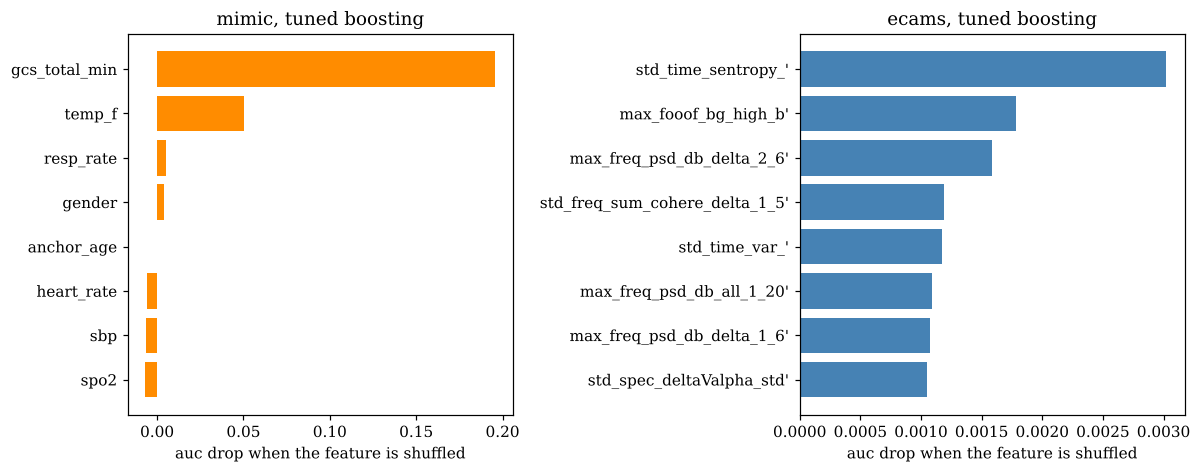

In [10]:
# figure, permutation importance for the tuned models, computed on held out folds
fig, ax = plt.subplots(1, 2, figsize = (11, 4.4))
for i, name in enumerate(data):
    X, y = data[name]
    best = fitted[(name, 'gradient boosting, tuned inside folds')].best_params_
    imps = []
    for a, b in StratifiedKFold(5, shuffle = True, random_state = 3).split(X, y):
        m = make_pipeline(SimpleImputer(strategy = 'median'), GradientBoostingClassifier(random_state = 0, max_features = 'sqrt', **{k.split('__')[1]: v for k, v in best.items()})).fit(X.iloc[a], y.iloc[a])
        p = permutation_importance(m, X.iloc[b], y.iloc[b], scoring = 'roc_auc', n_repeats = 5, random_state = 0)
        imps.append(p.importances_mean)
    imp = pd.Series(np.mean(imps, axis = 0), index = X.columns).sort_values(ascending = False).head(8)
    ax[i].barh(imp.index[::-1], imp.values[::-1], color = 'darkorange' if name == 'mimic' else 'steelblue')
    ax[i].set_xlabel('auc drop when the feature is shuffled')
    ax[i].set_title(name + ', tuned boosting')
    print(name, imp.round(3).to_dict())
plt.tight_layout()
plt.savefig('figs/w9_importance.png', dpi = 200)
plt.show()

Importance is very concentrated on MIMIC and almost flat on ECAMS. On MIMIC shuffling gcs_total_min drops the auc by 0.20 and temp_f by 0.05, and everything else is under 0.01 or slightly negative, so most of the vitals aren't contributing. On ECAMS the top feature (std_time_sentropy) only drops the auc by 0.003 and the rest are smaller, because the model can get the same information from many near copies and shuffling one barely matters. That is the same result as the forest importance in Milestone One. The EEG ranking tells me which feature groups are used, mostly variability of delta band power and coherence, but not that any single feature is the driver.

To sum up, boosting reached about 0.76 on MIMIC and 0.89 on ECAMS, about the same as the other tuned models. The main overfitting lesson is that training auc goes to 1.0 almost immediately while validation peaks in the first 30 to 100 rounds on MIMIC, so rounds, learning rate and depth are really one knob that sets how fast the model memorizes.